# Diferença pareada de RMSE com IC 95% por bootstrap em blocos

**Experimento:** calibração da previsão de MP2,5 do CAMS (rodada 00 UTC, leads de 0 a 3 dias) para a **média de 5 estações** do município de São Paulo (98 Grajaú-Parelheiros, 270 Marginal Tietê, 73 Congonhas, 95 Cidade Universitária, 83 Ibirapuera). Os modelos usam só a previsão do CAMS, as observações até *t*−1 e o calendário, sem reanálise, que não existe na manhã de *t*.

O runner do pm25bench calcula um intervalo de confiança para cada modelo separadamente. Dois intervalos que se sobrepõem não dizem se um modelo é melhor que o outro: os erros dos dois modelos nos mesmos dias são correlacionados (os dias difíceis são difíceis para todos), e essa correlação some quando cada intervalo é calculado sozinho. A pergunta certa é sobre a **diferença** de métricas, calculada nas mesmas reamostras para os dois modelos.

Convenção de sinal: B é sempre o `gbm_previsao`. Uma diferença **positiva** quer dizer que o RMSE de A é maior, ou seja, que o `gbm_previsao` erra menos.

## 1. Previsões e configuração

`predictions.csv` tem uma linha por modelo, data de emissão e lead, com a observação (`obs`) e a previsão (`pred`) em µg/m³. Como o benchmark avalia todos os modelos nas mesmas amostras, cada par (`issue_date`, `lead`) aparece uma vez para cada modelo, e é isso que permite o pareamento.

In [1]:
# os: troca do diretório de trabalho
import os

# Path: caminhos de arquivos
from pathlib import Path

# matplotlib: gráficos
import matplotlib.pyplot as plt

# pandas: tabelas
import pandas as pd

# leitura da configuração e divisão temporal do benchmark
from pm25bench import load_config, split_by_time

# RMSE com a mesma implementação usada pelo runner
from pm25bench.metrics import rmse

# bootstrap pareado e tabela de diferenças (pm25bench_calibracao/avaliacao.py)
from pm25bench_calibracao.avaliacao import tabela_diferencas

# tabela da média das estações (pm25bench_calibracao/media.py)
from pm25bench_calibracao.media import tabela_media

# raiz do plugin: o notebook roda de dentro de notebooks/ ou da raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# os caminhos da config (sisam_dir, cetesb_dir...) são relativos à raiz do plugin
os.chdir(RAIZ)
# configuração do experimento
cfg = load_config("configs/benchmark_media_sp5_previsao.yaml")
# previsões gravadas pelo scripts/rodar_media.py
pred = pd.read_csv(
    Path(cfg.output_dir) / "predictions.csv", parse_dates=["issue_date", "target_date"]
)
# modelos e número de linhas de cada um (deve ser igual: amostras × leads)
print(pred.groupby("model").size())

model
climatology        2076
dom_previsao       2076
forecast_raw       2076
gbm_previsao       2076
linear_previsao    2076
persistence        2076
dtype: int64


## 2. P90 da observação, calculado só no treino

O limiar que define "dia extremo" é o percentil 90 da observação diária **no período de treino**. Se ele fosse calculado no teste, a definição de extremo dependeria dos próprios dados avaliados, e essa informação do teste vazaria para a regra de avaliação.

In [2]:
# tabela diária da média das estações (a mesma usada pelo rodar_media.py)
df = tabela_media(
    cfg.data.sisam_dir,
    cfg.data.cetesb_dir,
    cfg.data.cams_forecast_dir,
    min_hours=cfg.data.min_hours,
)
# divisão em blocos de tempo com os cortes do YAML
treino, validacao, teste = split_by_time(
    df, cfg.data.train_end, cfg.data.val_end, cfg.data.gap_days
)
# percentil 90 das observações válidas do treino
P90 = float(treino["obs"].dropna().quantile(0.90))
# mostra o limiar
print(f"P90 do treino: {P90:.1f} µg/m³")

P90 do treino: 30.3 µg/m³


## 3. Bootstrap pareado por blocos

**Bootstrap.** A distribuição da diferença de RMSE é aproximada reamostrando os dados com reposição muitas vezes e recalculando a diferença em cada reamostra. Os quantis de 2,5% e 97,5% das réplicas formam o intervalo de confiança de 95%.

**Blocos.** O MP2,5 diário é autocorrelacionado: o erro de hoje se parece com o de ontem. Reamostrar dias isolados trataria dias vizinhos como independentes e produziria intervalos estreitos demais. Por isso os dias são agrupados em blocos de 7 dias consecutivos, e são os blocos inteiros que entram ou saem de cada reamostra.

**Pareamento.** Em cada reamostra, os **mesmos blocos** entram no cálculo dos dois modelos. A variância da diferença é `Var(A) + Var(B) − 2·Cov(A, B)`; como os dois modelos erram mais nos mesmos dias, a covariância é positiva e o intervalo da diferença fica mais estreito do que o que se deduziria comparando os dois intervalos separados.

A diferença é significativa a 95% quando o intervalo não contém zero. O código está em `src/pm25bench_calibracao/avaliacao.py` (função `bootstrap_diferenca_pareada`).

## 4. Tabela por lead

Quatro comparações contra o `gbm_previsao`: `linear_previsao` (mesmas entradas, sem não linearidade), `dom_previsao` (reta local na janela de 6 dias), `persistence` e `forecast_raw` (a previsão do CAMS sem correção).

A segunda tabela repete as contas só nos dias em que a observação passa do P90 do treino. Esse subconjunto é escolhido pelo valor observado, então ele mede como cada modelo se sai nos extremos, e não serve sozinho para escolher um modelo.

In [3]:
# modelo de referência (B)
REFERENCIA = "gbm_previsao"
# modelos comparados com a referência (A)
COMPARADOS = ["linear_previsao", "dom_previsao", "persistence", "forecast_raw"]
# parâmetros do bootstrap iguais aos do benchmark
args = dict(block_days=cfg.block_days, n_boot=cfg.n_boot, seed=cfg.seed)
# todas as amostras de teste
tab_todas = tabela_diferencas(pred, REFERENCIA, COMPARADOS, rmse, **args)
# só os dias com observação acima do P90 do treino
pred_p90 = pred[pred["obs"] > P90]
# diferenças no subconjunto de extremos
tab_p90 = tabela_diferencas(pred_p90, REFERENCIA, COMPARADOS, rmse, **args)
# quantas amostras de extremo há em cada lead
print(
    "amostras com obs > P90 por lead:",
    pred_p90[pred_p90["model"] == REFERENCIA].groupby("lead").size().to_dict(),
)
# tabela de todas as amostras
display(tab_todas.round(2))

amostras com obs > P90 por lead: {0: 53, 1: 54, 2: 53, 3: 53}


,modelo,lead,n,dif,ic_lo,ic_hi,significativa
0,linear_previsao,0,519,-0.72,-1.47,0.00,False
1,dom_previsao,0,519,2.02,0.14,4.53,True
2,persistence,0,519,0.54,-0.36,1.53,False
3,forecast_raw,0,519,7.63,4.81,10.39,True
4,linear_previsao,1,519,-0.01,-0.41,0.38,False
5,dom_previsao,1,519,2.89,0.28,5.46,True
6,persistence,1,519,2.89,1.96,3.76,True
7,forecast_raw,1,519,7.96,4.96,10.83,True
8,linear_previsao,2,519,0.15,-0.27,0.68,False
9,dom_previsao,2,519,3.58,0.23,7.19,True


In [4]:
# tabela restrita aos extremos (obs > P90 do treino)
display(tab_p90.round(2))

,modelo,lead,n,dif,ic_lo,ic_hi,significativa
0,linear_previsao,0,53,-3.79,-6.70,-0.35,True
1,dom_previsao,0,53,-2.42,-6.00,1.49,False
2,persistence,0,53,-5.12,-7.78,-2.06,True
3,forecast_raw,0,53,2.73,-1.43,8.16,False
4,linear_previsao,1,54,-1.41,-2.24,-0.14,True
5,dom_previsao,1,54,-2.09,-4.44,0.47,False
6,persistence,1,54,-2.75,-5.39,-0.11,True
7,forecast_raw,1,54,4.03,-2.12,11.56,False
8,linear_previsao,2,53,-0.84,-1.55,0.08,False
9,dom_previsao,2,53,-1.92,-3.63,0.59,False


## 5. Gráfico

Um painel por comparação. Cada ponto é a diferença de RMSE em um lead, e a barra é o IC 95%. Barras inteiramente acima de zero indicam que o `gbm_previsao` erra menos; inteiramente abaixo, que o outro modelo erra menos. A mesma figura, em versão para o relatório, é gerada por `scripts/figuras.py`.

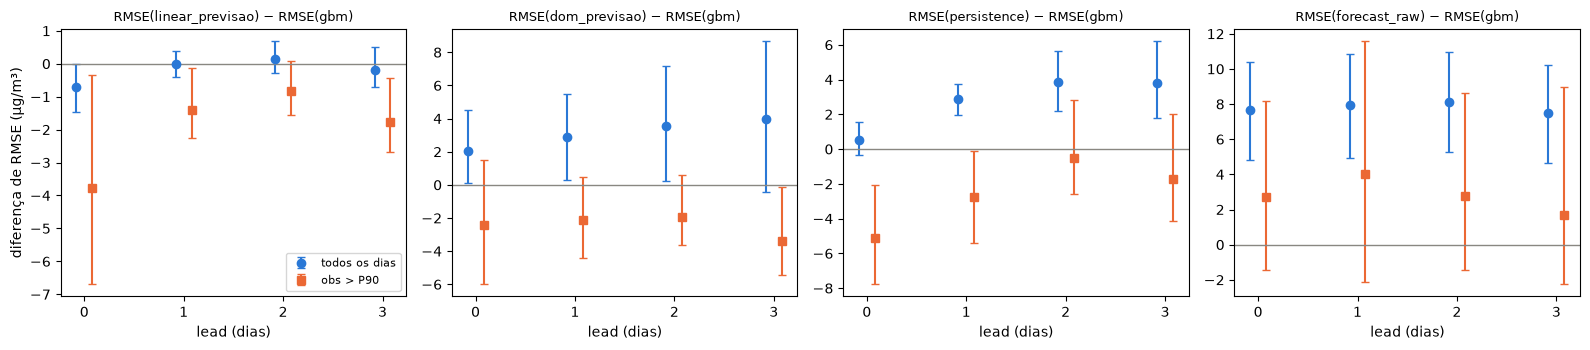

In [5]:
# um painel por comparação
fig, eixos = plt.subplots(1, len(COMPARADOS), figsize=(4 * len(COMPARADOS), 3.6), sharey=False)
# percorre comparações e painéis juntos
for ax, nome in zip(eixos, COMPARADOS, strict=True):
    # duas séries: todas as amostras e só os extremos
    for tab, rotulo, desloc, cor, marca in [
        (tab_todas, "todos os dias", -0.08, "#2a78d6", "o"),
        (tab_p90, "obs > P90", 0.08, "#eb6834", "s"),
    ]:
        # linhas desta comparação
        t = tab[tab["modelo"] == nome]
        # ponto com barra do IC
        ax.errorbar(
            t["lead"] + desloc,
            t["dif"],
            yerr=[t["dif"] - t["ic_lo"], t["ic_hi"] - t["dif"]],
            fmt=marca,
            capsize=3,
            color=cor,
            label=rotulo,
        )
    # linha em zero
    ax.axhline(0, color="#898781", lw=1)
    # título
    ax.set_title(f"RMSE({nome}) − RMSE(gbm)", fontsize=9)
    # leads inteiros
    ax.set_xticks([0, 1, 2, 3])
    # eixo x
    ax.set_xlabel("lead (dias)")
# eixo y e legenda só no primeiro painel
eixos[0].set_ylabel("diferença de RMSE (µg/m³)")
# legenda
eixos[0].legend(fontsize=8)
# espaçamento
fig.tight_layout()
# mostra
plt.show()